# Camera-Ready Merged Final Pipeline

**Three-class current stress classification:** 0 = No Stress, 1 = Low Stress, 2 = High Stress.  
**Exploratory future stress-state forecasting:** primary horizons 30, 60, 120, 300 seconds; 5 seconds retained only as an optional short-horizon appendix comparison, not the headline result.

This is the merged version combining:
- Explicit frozen participant IDs (not auto-generated by sorting/slicing)
- Validation-first model selection for classification (never pick a model by looking at test scores)
- Full baseline suite: majority, logistic regression, random forest, persistence, direct proxy-rule
- GRU, LSTM, Attention-GRU for both classification and forecasting
- **Actual-timestamp-based forecasting** (searches real timestamps for the nearest valid future point within a per-horizon tolerance, instead of assuming a fixed 32 Hz sample rate)
- Session-safe, gap-safe, participant-disjoint windows throughout, with explicit audits

Do not use the old class-wise row sampling or random split of already-created overlapping windows. Do not treat the 5-second horizon as the primary forecasting claim.

In [22]:
# CELL 1 — Setup
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

from pathlib import Path
import os
import gc
import random
import zipfile
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix, roc_auc_score
)

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, GRU, LSTM, Dense, Dropout, Layer
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path('/content/drive/MyDrive/dl research project')
LOCAL_DATA_DIR = Path('/content/kaggle_nurse_dataset')
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_CANDIDATES = [
    PROJECT_DIR / 'Paper_nurse_dataset.zip',
    PROJECT_DIR / 'Papernursedataset.zip',
    PROJECT_DIR / 'Nursedataset.zip',
]

FEATURES = ['HR', 'EDA', 'TEMP', 'X', 'Y', 'Z']
TARGET = 'label'
ID_COL = 'id'
TIME_COL = 'datetime'
CLASS_LABELS = np.array([0, 1, 2], dtype=np.int32)
CLASS_NAMES = ['No Stress', 'Low Stress', 'High Stress']

SEQUENCE_LENGTH = 32
WINDOW_STRIDE = 8
GAP_THRESHOLD_SECONDS = 5.0
MAX_WINDOW_GAP_SECONDS = 5.0

# EXPLICIT FROZEN SPLIT. Do not regenerate this by sorting/slicing participants,
# and do not change it after seeing any validation or test result.
TRAIN_IDS = ['15', '6B', '6D', '8B', 'BG', 'DF', 'E4', 'EG', 'F5']
VAL_IDS = ['7A', '7E', 'CE']
TEST_IDS = ['5C', '83', '94']

# Primary forecasting horizons (what the paper should report as the main forecasting result).
PRIMARY_FORECAST_HORIZONS_SECONDS = [30, 60, 120, 300]
# Optional secondary/appendix horizon only — do not present this as the headline forecasting result.
SECONDARY_FORECAST_HORIZONS_SECONDS = [5]

# Per-horizon tolerance for matching an actual future timestamp to the requested horizon.
HORIZON_TOLERANCE_SECONDS = {
    5: 0.5,
    30: 1.0,
    60: 1.0,
    120: 2.0,
    300: 5.0,
}

EPOCHS = 30
BATCH_SIZE = 256
REPEAT_SEEDS = [42, 52, 62, 72, 82]

print('Setup complete')
print('Project directory:', PROJECT_DIR)
print('Sequence length:', SEQUENCE_LENGTH)
print('Primary forecast horizons (seconds):', PRIMARY_FORECAST_HORIZONS_SECONDS)
print('Secondary/appendix forecast horizons (seconds):', SECONDARY_FORECAST_HORIZONS_SECONDS)
print('Frozen train IDs:', TRAIN_IDS)
print('Frozen validation IDs:', VAL_IDS)
print('Frozen test IDs:', TEST_IDS)


Mounted at /content/drive
Setup complete
Project directory: /content/drive/MyDrive/dl research project
Sequence length: 32
Primary forecast horizons (seconds): [30, 60, 120, 300]
Secondary/appendix forecast horizons (seconds): [5]
Frozen train IDs: ['15', '6B', '6D', '8B', 'BG', 'DF', 'E4', 'EG', 'F5']
Frozen validation IDs: ['7A', '7E', 'CE']
Frozen test IDs: ['5C', '83', '94']


In [2]:
# CELL 2 — Load original dataset
DATASET_ZIP = next((p for p in ZIP_CANDIDATES if p.exists()), None)
if DATASET_ZIP is None:
    raise FileNotFoundError(
        'Dataset ZIP not found. Expected one of:\n' + '\n'.join(str(p) for p in ZIP_CANDIDATES)
    )

csv_files = list(LOCAL_DATA_DIR.rglob('*.csv'))
if not csv_files:
    print('Extracting:', DATASET_ZIP)
    with zipfile.ZipFile(DATASET_ZIP, 'r') as zf:
        zf.extractall(LOCAL_DATA_DIR)
    csv_files = list(LOCAL_DATA_DIR.rglob('*.csv'))

if not csv_files:
    raise FileNotFoundError('No CSV file found after extraction.')

merged = [p for p in csv_files if p.name.lower() == 'merged_data.csv']
CSV_PATH = merged[0] if merged else csv_files[0]

print('Using CSV:', CSV_PATH)
print('CSV size (MB):', round(CSV_PATH.stat().st_size / 1024**2, 2))

df = pd.read_csv(
    CSV_PATH,
    usecols=FEATURES + [ID_COL, TIME_COL, TARGET],
    low_memory=False
)

print('Raw dataframe shape:', df.shape)
display(df.head())


Extracting: /content/drive/MyDrive/dl research project/Paper_nurse_dataset.zip
Using CSV: /content/kaggle_nurse_dataset/merged_data.csv
CSV size (MB): 821.18
Raw dataframe shape: (11509051, 9)


,X,Y,Z,EDA,HR,TEMP,id,datetime,label
0,-13.0,-61.0,5.0,6.769995,99.43,31.17,15,2020-07-08 14:03:00.000000000,2.0
1,-20.0,-69.0,-3.0,6.769995,99.43,31.17,15,2020-07-08 14:03:00.031249920,2.0
2,-31.0,-78.0,-15.0,6.769995,99.43,31.17,15,2020-07-08 14:03:00.062500096,2.0
3,-47.0,-65.0,-38.0,6.769995,99.43,31.17,15,2020-07-08 14:03:00.093750016,2.0
4,-67.0,-57.0,-53.0,6.769995,99.43,31.17,15,2020-07-08 14:03:00.124999936,2.0


In [3]:
# CELL 3 — Cleaning, label audit, and session inference
df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors='coerce')
for col in FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[ID_COL] = df[ID_COL].astype(str).str.strip()
df = df.dropna(subset=[ID_COL, TIME_COL, TARGET]).copy()
df[TARGET] = df[TARGET].astype(np.int32)

unexpected = set(df[TARGET].unique()) - set(CLASS_LABELS)
if unexpected:
    raise ValueError(f'Unexpected labels: {unexpected}')

df = df.sort_values([ID_COL, TIME_COL]).reset_index(drop=True)
df['gap_seconds'] = df.groupby(ID_COL)[TIME_COL].diff().dt.total_seconds()
df['new_session'] = (
    df['gap_seconds'].isna()
    | (df['gap_seconds'] > GAP_THRESHOLD_SECONDS)
    | (df['gap_seconds'] <= 0)
).astype(np.int8)
df['session_number'] = df.groupby(ID_COL)['new_session'].cumsum().astype(np.int32)
df['session_id'] = df[ID_COL] + '_' + df['session_number'].astype(str)

label_counts = df[TARGET].value_counts().reindex(CLASS_LABELS, fill_value=0)
label_audit = pd.DataFrame({
    'class': CLASS_NAMES,
    'count': label_counts.to_numpy(),
    'percent': (100 * label_counts / label_counts.sum()).round(3).to_numpy(),
})

missingness = pd.DataFrame({
    'feature': FEATURES,
    'missing_percent_before_imputation': (100 * df[FEATURES].isna().mean()).round(4).to_numpy(),
})

participant_summary = df.groupby(ID_COL).agg(
    rows=(TARGET, 'size'),
    sessions=('session_id', 'nunique'),
    start_time=(TIME_COL, 'min'),
    end_time=(TIME_COL, 'max'),
).reset_index()
participant_summary['duration_hours'] = (
    (participant_summary['end_time'] - participant_summary['start_time']).dt.total_seconds() / 3600
)

print('Rows after cleaning:', len(df))
print('Participants:', df[ID_COL].nunique())
print('Participant IDs:', sorted(df[ID_COL].unique()))
print('Inferred sessions:', df['session_id'].nunique())
print('Gaps > 5 seconds:', int((df['gap_seconds'] > GAP_THRESHOLD_SECONDS).sum()))
print('Non-positive gaps:', int((df['gap_seconds'] <= 0).sum()))
print('\nRow-level label distribution:')
display(label_audit)
print('\nFeature missingness:')
display(missingness)
print('\nPer-participant summary:')
display(participant_summary)

label_audit.to_csv(PROJECT_DIR / 'merged_row_label_audit.csv', index=False)
missingness.to_csv(PROJECT_DIR / 'merged_missingness_audit.csv', index=False)
participant_summary.to_csv(PROJECT_DIR / 'merged_participant_summary.csv', index=False)


Rows after cleaning: 11509051
Participants: 15
Participant IDs: ['15', '5C', '6B', '6D', '7A', '7E', '83', '8B', '94', 'BG', 'CE', 'DF', 'E4', 'EG', 'F5']
Inferred sessions: 105818
Gaps > 5 seconds: 196
Non-positive gaps: 105607

Row-level label distribution:


,class,count,percent
0,No Stress,2162246,18.787
1,Low Stress,806222,7.005
2,High Stress,8540583,74.208



Feature missingness:


,feature,missing_percent_before_imputation
0,HR,0.0
1,EDA,0.0
2,TEMP,0.0
3,X,0.0
4,Y,0.0
5,Z,0.0



Per-participant summary:


,id,rows,sessions,start_time,end_time,duration_hours
0,15,309131,11,2020-07-08 13:09:00,2020-07-31 20:13:00,559.066667
1,5C,865930,10,2020-04-14 22:31:00,2020-06-25 17:26:00,1722.916667
2,6B,825549,7693,2020-06-23 15:46:00,2020-06-30 15:39:00,167.883333
3,6D,591363,3,2020-07-16 14:49:00,2020-07-16 20:19:00,5.500000
4,7A,1377342,32673,2020-04-18 18:52:00,2020-07-07 13:44:00,1914.866667
5,7E,253447,7,2020-10-21 18:46:00,2020-11-05 20:50:00,362.066667
6,83,1372819,19,2020-10-30 06:25:00,2020-12-13 08:01:00,1057.600000
7,8B,423763,15,2020-07-15 12:56:00,2020-07-22 19:08:00,174.200000
8,94,586096,16,2020-05-09 22:28:00,2020-07-07 12:54:00,1406.433333
9,BG,608655,15,2020-10-29 00:30:00,2020-12-12 01:38:00,1057.133333


In [4]:
# CELL 4 — Frozen participant-disjoint split (explicit, hardcoded, not searched or sorted/sliced)
all_ids = set(df[ID_COL].unique())
requested_ids = set(TRAIN_IDS + VAL_IDS + TEST_IDS)
missing_ids = requested_ids - all_ids

if missing_ids:
    raise ValueError(f'Missing expected participant IDs: {missing_ids}. Available: {sorted(all_ids)}')

assert set(TRAIN_IDS).isdisjoint(VAL_IDS)
assert set(TRAIN_IDS).isdisjoint(TEST_IDS)
assert set(VAL_IDS).isdisjoint(TEST_IDS)

train_df = df[df[ID_COL].isin(TRAIN_IDS)].copy()
val_df = df[df[ID_COL].isin(VAL_IDS)].copy()
test_df = df[df[ID_COL].isin(TEST_IDS)].copy()

def row_distribution(split_df):
    counts = split_df[TARGET].value_counts().reindex(CLASS_LABELS, fill_value=0)
    return (100 * counts / counts.sum()).round(3)

row_summary = pd.DataFrame(
    [row_distribution(train_df), row_distribution(val_df), row_distribution(test_df)],
    index=['Train', 'Validation', 'Test']
)
row_summary.columns = CLASS_NAMES

# Detailed per-participant row-level distribution audit (kept from the more thorough audit notebook).
participant_class_counts = pd.crosstab(df[ID_COL], df[TARGET]).reindex(columns=CLASS_LABELS, fill_value=0)
participant_class_counts.columns = CLASS_NAMES
participant_class_counts['Total'] = participant_class_counts.sum(axis=1)
participant_class_pct = (
    participant_class_counts[CLASS_NAMES].div(participant_class_counts['Total'], axis=0) * 100
)

print('Frozen participant-disjoint split (explicitly hardcoded)')
print('Train:', TRAIN_IDS)
print('Validation:', VAL_IDS)
print('Test:', TEST_IDS)
print('\nRow-level class proportions by split (%)')
display(row_summary)
print('\nPer-participant row-level counts:')
display(participant_class_counts)
print('\nPer-participant row-level percentages:')
display(participant_class_pct.round(2))

row_summary.to_csv(PROJECT_DIR / 'merged_frozen_split_row_proportions.csv')
participant_class_counts.to_csv(PROJECT_DIR / 'merged_participant_row_counts.csv')
participant_class_pct.to_csv(PROJECT_DIR / 'merged_participant_row_percentages.csv')

with open(PROJECT_DIR / 'merged_frozen_split.json', 'w') as f:
    json.dump({'train': TRAIN_IDS, 'validation': VAL_IDS, 'test': TEST_IDS}, f, indent=2)

print('PASS: participant sets are disjoint and frozen before final evaluation.')


Frozen participant-disjoint split (explicitly hardcoded)
Train: ['15', '6B', '6D', '8B', 'BG', 'DF', 'E4', 'EG', 'F5']
Validation: ['7A', '7E', 'CE']
Test: ['5C', '83', '94']

Row-level class proportions by split (%)


,No Stress,Low Stress,High Stress
Train,18.601,0.246,81.153
Validation,6.675,16.676,76.648
Test,29.682,13.563,56.754



Per-participant row-level counts:


,No Stress,Low Stress,High Stress,Total
id,,,,
15,13441,0,295690,309131
5C,309121,295685,261124,865930
6B,107522,0,718027,825549
6D,503041,0,88322,591363
7A,46082,388517,942743,1377342
7E,117124,0,136323,253447
83,163204,0,1209615,1372819
8B,138243,0,285520,423763
94,366153,87458,132485,586096



Per-participant row-level percentages:


,No Stress,Low Stress,High Stress
id,,,
15,4.35,0.00,95.65
5C,35.70,34.15,30.16
6B,13.02,0.00,86.98
6D,85.06,0.00,14.94
7A,3.35,28.21,68.45
7E,46.21,0.00,53.79
83,11.89,0.00,88.11
8B,32.62,0.00,67.38
94,62.47,14.92,22.60


PASS: participant sets are disjoint and frozen before final evaluation.


In [5]:
# CELL 5 — Train-only preprocessing
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

train_values = imputer.fit_transform(train_df[FEATURES])
val_values = imputer.transform(val_df[FEATURES])
test_values = imputer.transform(test_df[FEATURES])

train_df.loc[:, FEATURES] = scaler.fit_transform(train_values)
val_df.loc[:, FEATURES] = scaler.transform(val_values)
test_df.loc[:, FEATURES] = scaler.transform(test_values)

preprocessing_audit = pd.DataFrame({
    'feature': FEATURES,
    'training_median_imputation': imputer.statistics_,
    'training_scaler_mean': scaler.mean_,
    'training_scaler_scale': scaler.scale_,
})

display(preprocessing_audit)
preprocessing_audit.to_csv(PROJECT_DIR / 'merged_preprocessing_audit.csv', index=False)
print('PASS: imputer fitted only on training participants.')
print('PASS: scaler fitted only on training participants.')


,feature,training_median_imputation,training_scaler_mean,training_scaler_scale
0,HR,84.820000,86.659691,14.432018
1,EDA,1.006302,4.069051,6.365164
2,TEMP,31.990000,32.025906,2.104400
3,X,-25.000000,-20.592181,34.935414
4,Y,2.000000,1.828085,33.814900
5,Z,27.000000,25.767620,28.737243


PASS: imputer fitted only on training participants.
PASS: scaler fitted only on training participants.


In [6]:
# CELL 6 — Session-safe current-stress sequences and explicit audits
def create_sequences(data, feature_cols, target_col, seq_len, stride, max_gap):
    X_list, y_list, meta_list = [], [], []
    ordered = data.sort_values([ID_COL, 'session_id', TIME_COL]).copy()

    for (participant_id, session_id), group in ordered.groupby([ID_COL, 'session_id'], sort=False):
        group = group.sort_values(TIME_COL).reset_index(drop=True)
        if len(group) < seq_len:
            continue

        values = group[feature_cols].to_numpy(dtype=np.float32)
        labels = group[target_col].to_numpy(dtype=np.int32)
        times = group[TIME_COL].to_numpy()
        gaps = group[TIME_COL].diff().dt.total_seconds().to_numpy()

        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            internal_gaps = gaps[start + 1:end]
            if np.any(internal_gaps > max_gap):
                continue

            max_internal_gap = float(np.nanmax(internal_gaps)) if len(internal_gaps) else 0.0
            X_list.append(values[start:end])
            y_list.append(labels[end - 1])
            meta_list.append({
                'id': participant_id,
                'session_id': session_id,
                'start_time': times[start],
                'end_time': times[end - 1],
                'max_internal_gap_seconds': max_internal_gap,
            })

    if not X_list:
        raise RuntimeError('No valid windows created.')

    return np.stack(X_list).astype(np.float32), np.asarray(y_list, dtype=np.int32), pd.DataFrame(meta_list)

print('Creating session-safe current-stress windows...')
X_train, y_train, meta_train = create_sequences(
    train_df, FEATURES, TARGET, SEQUENCE_LENGTH, WINDOW_STRIDE, MAX_WINDOW_GAP_SECONDS
)
X_val, y_val, meta_val = create_sequences(
    val_df, FEATURES, TARGET, SEQUENCE_LENGTH, WINDOW_STRIDE, MAX_WINDOW_GAP_SECONDS
)
X_test, y_test, meta_test = create_sequences(
    test_df, FEATURES, TARGET, SEQUENCE_LENGTH, WINDOW_STRIDE, MAX_WINDOW_GAP_SECONDS
)

assert set(np.unique(y_train)) == set(CLASS_LABELS)
assert set(np.unique(y_val)) == set(CLASS_LABELS)
assert set(np.unique(y_test)) == set(CLASS_LABELS)

assert set(meta_train['id']).isdisjoint(set(meta_val['id']))
assert set(meta_train['id']).isdisjoint(set(meta_test['id']))
assert set(meta_val['id']).isdisjoint(set(meta_test['id']))

assert (meta_train['max_internal_gap_seconds'] <= MAX_WINDOW_GAP_SECONDS).all()
assert (meta_val['max_internal_gap_seconds'] <= MAX_WINDOW_GAP_SECONDS).all()
assert (meta_test['max_internal_gap_seconds'] <= MAX_WINDOW_GAP_SECONDS).all()

def window_distribution(labels):
    counts = pd.Series(labels).value_counts().reindex(CLASS_LABELS, fill_value=0)
    return pd.DataFrame({
        'class': CLASS_NAMES,
        'count': counts.to_numpy(),
        'percent': (100 * counts / counts.sum()).round(3).to_numpy(),
    })

print('Train shape:', X_train.shape)
print('Validation shape:', X_val.shape)
print('Test shape:', X_test.shape)
print('\nTraining window distribution:')
display(window_distribution(y_train))
print('\nValidation window distribution:')
display(window_distribution(y_val))
print('\nTest window distribution:')
display(window_distribution(y_test))

# Detailed per-participant window-level distribution audit (post window-construction, not just row-level).
all_meta = pd.concat([
    meta_train.assign(split='Train', label=y_train),
    meta_val.assign(split='Validation', label=y_val),
    meta_test.assign(split='Test', label=y_test),
], ignore_index=True)

window_participant_counts = pd.crosstab(all_meta['id'], all_meta['label']).reindex(columns=CLASS_LABELS, fill_value=0)
window_participant_counts.columns = CLASS_NAMES
window_participant_counts['Total'] = window_participant_counts.sum(axis=1)
print('\nPer-participant WINDOW-level label counts (post window construction):')
display(window_participant_counts)
window_participant_counts.to_csv(PROJECT_DIR / 'merged_participant_window_distribution.csv')

meta_train.to_csv(PROJECT_DIR / 'merged_train_window_metadata.csv', index=False)
meta_val.to_csv(PROJECT_DIR / 'merged_validation_window_metadata.csv', index=False)
meta_test.to_csv(PROJECT_DIR / 'merged_test_window_metadata.csv', index=False)

print('PASS: all three classes occur in each split.')
print('PASS: no participant overlaps across splits.')
print('PASS: no classification window crosses a gap greater than 5 seconds.')


Creating session-safe current-stress windows...
Train shape: (761291, 32, 6)
Validation shape: (297308, 32, 6)
Test shape: (352965, 32, 6)

Training window distribution:


,class,count,percent
0,No Stress,145014,19.048
1,Low Stress,1917,0.252
2,High Stress,614360,80.700



Validation window distribution:


,class,count,percent
0,No Stress,20382,6.856
1,Low Stress,42782,14.390
2,High Stress,234144,78.755



Test window distribution:


,class,count,percent
0,No Stress,104766,29.682
1,Low Stress,47871,13.563
2,High Stress,200328,56.756



Per-participant WINDOW-level label counts (post window construction):


,No Stress,Low Stress,High Stress,Total
id,,,,
15,1677,0,36930,38607
5C,38637,36945,32628,108210
6B,13434,0,87799,101233
6D,62877,0,11034,73911
7A,5754,40385,117771,163910
7E,14628,0,17031,31659
83,20388,0,151155,171543
8B,17271,0,35652,52923
94,45741,10926,16545,73212


PASS: all three classes occur in each split.
PASS: no participant overlaps across splits.
PASS: no classification window crosses a gap greater than 5 seconds.


In [7]:
# CELL 7 — Common metrics and model-selection helper
def compute_metrics(y_true, y_pred, probabilities=None):
    out = {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': precision_score(y_true, y_pred, labels=CLASS_LABELS, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, labels=CLASS_LABELS, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, labels=CLASS_LABELS, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, y_pred, labels=CLASS_LABELS, average='weighted', zero_division=0),
    }
    if probabilities is not None:
        try:
            out['macro_ovr_auc'] = roc_auc_score(
                y_true, probabilities, labels=CLASS_LABELS, multi_class='ovr', average='macro'
            )
        except ValueError:
            out['macro_ovr_auc'] = np.nan
    else:
        out['macro_ovr_auc'] = np.nan
    return out

def print_evaluation(name, y_true, y_pred, probabilities=None):
    metrics = compute_metrics(y_true, y_pred, probabilities)
    print('\n' + '=' * 72)
    print(name)
    print('=' * 72)
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}' if not pd.isna(value) else f'{key}: NA')
    print('\nClassification report:')
    print(classification_report(
        y_true, y_pred, labels=CLASS_LABELS, target_names=CLASS_NAMES, digits=4, zero_division=0
    ))
    print('Confusion matrix:')
    print(confusion_matrix(y_true, y_pred, labels=CLASS_LABELS))
    return metrics


In [ ]:
# CELL 8 — Current-stress baselines and validation-first selection
majority_class = int(pd.Series(y_train).value_counts().idxmax())
majority_val_pred = np.full(len(y_val), majority_class, dtype=np.int32)
majority_test_pred = np.full(len(y_test), majority_class, dtype=np.int32)

print_evaluation('MAJORITY BASELINE — VALIDATION', y_val, majority_val_pred)
majority_test_metrics = print_evaluation('MAJORITY BASELINE — TEST', y_test, majority_test_pred)

def sequence_summary(X):
    return np.concatenate([
        X.mean(axis=1), X.std(axis=1), X.min(axis=1), X.max(axis=1),
    ], axis=1).astype(np.float32)

X_train_lr = sequence_summary(X_train)
X_val_lr = sequence_summary(X_val)
X_test_lr = sequence_summary(X_test)

logreg = LogisticRegression(
    max_iter=2000, class_weight='balanced', solver='saga', n_jobs=-1, random_state=SEED
)
print('Training logistic-regression baseline...')
logreg.fit(X_train_lr, y_train)

logreg_val_prob = logreg.predict_proba(X_val_lr)
logreg_val_pred = np.argmax(logreg_val_prob, axis=1).astype(np.int32)
logreg_val_metrics = print_evaluation(
    'LOGISTIC REGRESSION BASELINE — VALIDATION', y_val, logreg_val_pred, logreg_val_prob
)

# Baseline test result is shown for reporting, but do not select a model by test score.
logreg_test_prob = logreg.predict_proba(X_test_lr)
logreg_test_pred = np.argmax(logreg_test_prob, axis=1).astype(np.int32)
logreg_test_metrics = print_evaluation(
    'LOGISTIC REGRESSION BASELINE — TEST', y_test, logreg_test_pred, logreg_test_prob
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=SEED,
    verbose=1
)
print('Training random-forest baseline...')
rf.fit(X_train_lr, y_train)

rf_val_prob = rf.predict_proba(X_val_lr)
rf_val_pred = np.argmax(rf_val_prob, axis=1).astype(np.int32)
rf_val_metrics = print_evaluation(
    'RANDOM FOREST BASELINE — VALIDATION', y_val, rf_val_pred, rf_val_prob
)

rf_test_prob = rf.predict_proba(X_test_lr)
rf_test_pred = np.argmax(rf_test_prob, axis=1).astype(np.int32)
rf_test_metrics = print_evaluation(
    'RANDOM FOREST BASELINE — TEST', y_test, rf_test_pred, rf_test_prob
)



MAJORITY BASELINE — VALIDATION
accuracy: 0.7875
balanced_accuracy: 0.3333
macro_precision: 0.2625
macro_recall: 0.3333
macro_f1: 0.2937
weighted_f1: 0.6939
macro_ovr_auc: NA

Classification report:
              precision    recall  f1-score   support

   No Stress     0.0000    0.0000    0.0000     20382
  Low Stress     0.0000    0.0000    0.0000     42782
 High Stress     0.7875    1.0000    0.8811    234144

    accuracy                         0.7875    297308
   macro avg     0.2625    0.3333    0.2937    297308
weighted avg     0.6202    0.7875    0.6939    297308

Confusion matrix:
[[     0      0  20382]
 [     0      0  42782]
 [     0      0 234144]]

MAJORITY BASELINE — TEST
accuracy: 0.5676
balanced_accuracy: 0.3333
macro_precision: 0.1892
macro_recall: 0.3333
macro_f1: 0.2414
weighted_f1: 0.4110
macro_ovr_auc: NA

Classification report:
              precision    recall  f1-score   support

   No Stress     0.0000    0.0000    0.0000    104766
  Low Stress     0.0000    

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  9.8min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 10.0min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    2.7s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    2.8s finished



RANDOM FOREST BASELINE — VALIDATION
accuracy: 0.7267
balanced_accuracy: 0.3151
macro_precision: 0.2709
macro_recall: 0.3151
macro_f1: 0.2914
weighted_f1: 0.6715
macro_ovr_auc: 0.4853

Classification report:
              precision    recall  f1-score   support

   No Stress     0.0222    0.0247    0.0234     20382
  Low Stress     0.0000    0.0000    0.0000     42782
 High Stress     0.7906    0.9206    0.8507    234144

    accuracy                         0.7267    297308
   macro avg     0.2709    0.3151    0.2914    297308
weighted avg     0.6242    0.7267    0.6715    297308

Confusion matrix:
[[   503      0  19879]
 [  5581      0  37201]
 [ 16563   2031 215550]]


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    1.2s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    5.6s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    5.7s finished



RANDOM FOREST BASELINE — TEST
accuracy: 0.6051
balanced_accuracy: 0.4150
macro_precision: 0.3821
macro_recall: 0.4150
macro_f1: 0.3890
weighted_f1: 0.5455
macro_ovr_auc: 0.5698

Classification report:
              precision    recall  f1-score   support

   No Stress     0.5093    0.3750    0.4319    104766
  Low Stress     0.0005    0.0000    0.0000     47871
 High Stress     0.6365    0.8701    0.7351    200328

    accuracy                         0.6051    352965
   macro avg     0.3821    0.4150    0.3890    352965
weighted avg     0.5125    0.6051    0.5455    352965

Confusion matrix:
[[ 39287      0  65479]
 [ 13791      1  34079]
 [ 24064   1967 174297]]


In [ ]:
# CELL 9 — Three-class GRU and LSTM, using conservative training-only weights
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

class_weight_dict = {0: 1.0, 1: 2.0, 2: 0.75}
INPUT_SHAPE = (SEQUENCE_LENGTH, len(FEATURES))

print('Input shape:', INPUT_SHAPE)
print('Conservative class weights:', class_weight_dict)

def callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ]

def build_gru():
    model = Sequential([
        Input(shape=INPUT_SHAPE),
        GRU(64, return_sequences=True),
        Dropout(0.35),
        GRU(32),
        Dropout(0.35),
        Dense(24, activation='relu'),
        Dropout(0.25),
        Dense(3, activation='softmax'),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def build_lstm():
    model = Sequential([
        Input(shape=INPUT_SHAPE),
        LSTM(64, return_sequences=True),
        Dropout(0.35),
        LSTM(32),
        Dropout(0.35),
        Dense(24, activation='relu'),
        Dropout(0.25),
        Dense(3, activation='softmax'),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print('\nTRAINING GRU')
gru_model = build_gru()
gru_history = gru_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight_dict,
    callbacks=callbacks(), verbose=1
)

gru_val_prob = gru_model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
gru_val_pred = np.argmax(gru_val_prob, axis=1).astype(np.int32)
gru_val_metrics = print_evaluation('GRU — VALIDATION', y_val, gru_val_pred, gru_val_prob)

print('\nTRAINING LSTM')
lstm_model = build_lstm()
lstm_history = lstm_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight_dict,
    callbacks=callbacks(), verbose=1
)

lstm_val_prob = lstm_model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
lstm_val_pred = np.argmax(lstm_val_prob, axis=1).astype(np.int32)
lstm_val_metrics = print_evaluation('LSTM — VALIDATION', y_val, lstm_val_pred, lstm_val_prob)

selection_table = pd.DataFrame([
    {'Model': 'Logistic regression', **logreg_val_metrics},
    {'Model': 'Random forest', **rf_val_metrics},
    {'Model': 'GRU', **gru_val_metrics},
    {'Model': 'LSTM', **lstm_val_metrics},
]).sort_values('macro_f1', ascending=False)

print('\nMODEL SELECTION — VALIDATION ONLY')
display(selection_table.round(4))
print('Select the final model by validation macro-F1, not test performance.')


Input shape: (32, 6)
Conservative class weights: {0: 1.0, 1: 2.0, 2: 0.75}

TRAINING GRU
Epoch 1/30
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 468s 155ms/step - accuracy: 0.8323 - loss: 0.3462 - val_accuracy: 0.6317 - val_loss: 2.5365 - learning_rate: 5.0000e-04
Epoch 2/30
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 458s 154ms/step - accuracy: 0.8636 - loss: 0.2773 - val_accuracy: 0.6621 - val_loss: 2.9977 - learning_rate: 5.0000e-04
Epoch 3/30
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.8833 - loss: 0.2405
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 495s 152ms/step - accuracy: 0.8869 - loss: 0.2327 - val_accuracy: 0.6889 - val_loss: 3.5199 - learning_rate: 5.0000e-04
Epoch 4/30
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 491s 165ms/step - accuracy: 0.9011 - loss: 0.2005 - val_accuracy: 0.6953 - val_loss: 3.6902 - learning_rate: 2.5000e-04
Epoch 5/30
2974/2974 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.9078 - loss: 0.1884
Epoch 5: ReduceLRO

,Model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_auc
1,Random forest,0.7267,0.3151,0.2709,0.3151,0.2914,0.6715,0.4853
3,LSTM,0.6934,0.2953,0.2626,0.2953,0.2775,0.6516,0.3686
2,GRU,0.6317,0.2677,0.2513,0.2677,0.2588,0.6103,0.2898
0,Logistic regression,0.4018,0.1888,0.2345,0.1888,0.2015,0.4606,0.3850


Select the final model by validation macro-F1, not test performance.


In [ ]:
# CELL 10 — Frozen held-out test evaluation
gru_test_prob = gru_model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
gru_test_pred = np.argmax(gru_test_prob, axis=1).astype(np.int32)
gru_test_metrics = print_evaluation('GRU — FROZEN HELD-OUT PARTICIPANT TEST', y_test, gru_test_pred, gru_test_prob)

lstm_test_prob = lstm_model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
lstm_test_pred = np.argmax(lstm_test_prob, axis=1).astype(np.int32)
lstm_test_metrics = print_evaluation('LSTM — FROZEN HELD-OUT PARTICIPANT TEST', y_test, lstm_test_pred, lstm_test_prob)

classification_results = pd.DataFrame([
    {'Model': 'Majority baseline', **majority_test_metrics},
    {'Model': 'Logistic regression', **logreg_test_metrics},
    {'Model': 'Random forest', **rf_test_metrics},
    {'Model': 'GRU', **gru_test_metrics},
    {'Model': 'LSTM', **lstm_test_metrics},
])

print('\nFINAL THREE-CLASS CLASSIFICATION RESULTS')
display(classification_results.round(4))
classification_results.to_csv(PROJECT_DIR / 'merged_classification_results.csv', index=False)


1379/1379 ━━━━━━━━━━━━━━━━━━━━ 50s 36ms/step

GRU — FROZEN HELD-OUT PARTICIPANT TEST
accuracy: 0.5411
balanced_accuracy: 0.3573
macro_precision: 0.3402
macro_recall: 0.3573
macro_f1: 0.3313
weighted_f1: 0.4811
macro_ovr_auc: 0.6068

Classification report:
              precision    recall  f1-score   support

   No Stress     0.3460    0.2323    0.2779    104766
  Low Stress     0.0723    0.0103    0.0180     47871
 High Stress     0.6024    0.8295    0.6980    200328

    accuracy                         0.5411    352965
   macro avg     0.3402    0.3573    0.3313    352965
weighted avg     0.4544    0.5411    0.4811    352965

Confusion matrix:
[[ 24332     28  80406]
 [ 18133    493  29245]
 [ 27867   6298 166163]]
1379/1379 ━━━━━━━━━━━━━━━━━━━━ 61s 44ms/step

LSTM — FROZEN HELD-OUT PARTICIPANT TEST
accuracy: 0.5645
balanced_accuracy: 0.3786
macro_precision: 0.3663
macro_recall: 0.3786
macro_f1: 0.3539
weighted_f1: 0.5072
macro_ovr_auc: 0.6166

Classification report:
              p

,Model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_auc
0,Majority baseline,0.5676,0.3333,0.1892,0.3333,0.2414,0.4110,NaN
1,Logistic regression,0.5439,0.4110,0.4341,0.4110,0.4117,0.5249,0.5714
2,Random forest,0.6051,0.4150,0.3821,0.4150,0.3890,0.5455,0.5698
3,GRU,0.5411,0.3573,0.3402,0.3573,0.3313,0.4811,0.6068
4,LSTM,0.5645,0.3786,0.3663,0.3786,0.3539,0.5072,0.6166


In [ ]:
# CELL 11 — Repeated GRU/LSTM runs on the SAME frozen split (robustness check, not model selection)
# The split never changes here. Only the random initialization seed changes.
repeat_rows = []

for seed in REPEAT_SEEDS:
    print('\n' + '=' * 72)
    print(f'REPEAT SEED {seed}')
    print('=' * 72)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_gru()
    model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight_dict,
        callbacks=callbacks(), verbose=0
    )
    prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    pred = np.argmax(prob, axis=1)
    metrics = compute_metrics(y_test, pred, prob)
    repeat_rows.append({'seed': seed, 'model': 'GRU', **metrics})

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_lstm()
    model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight_dict,
        callbacks=callbacks(), verbose=0
    )
    prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    pred = np.argmax(prob, axis=1)
    metrics = compute_metrics(y_test, pred, prob)
    repeat_rows.append({'seed': seed, 'model': 'LSTM', **metrics})

repeated_results = pd.DataFrame(repeat_rows)
print('\nIndividual repeated-run results:')
display(repeated_results.round(4))

repeated_summary = repeated_results.groupby('model').agg(
    accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'),
    macro_f1_mean=('macro_f1', 'mean'), macro_f1_sd=('macro_f1', 'std'),
    balanced_accuracy_mean=('balanced_accuracy', 'mean'), balanced_accuracy_sd=('balanced_accuracy', 'std'),
).reset_index()

print('\nRepeated-run summary (mean ± SD across seeds, same frozen split):')
display(repeated_summary.round(4))

repeated_results.to_csv(PROJECT_DIR / 'merged_repeated_runs.csv', index=False)
repeated_summary.to_csv(PROJECT_DIR / 'merged_repeated_runs_summary.csv', index=False)



REPEAT SEED 42

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


In [ ]:
# CELL 12 — Optional participant-level 5-fold group CV (classical models; robustness analysis, not model selection)
try:
    from sklearn.model_selection import StratifiedGroupKFold
    _splitter_cls = StratifiedGroupKFold
except ImportError:
    from sklearn.model_selection import GroupKFold
    _splitter_cls = GroupKFold

X_all_raw = np.concatenate([X_train, X_val, X_test], axis=0)
y_all = np.concatenate([y_train, y_val, y_test], axis=0)
groups_all = np.concatenate([meta_train['id'].to_numpy(), meta_val['id'].to_numpy(), meta_test['id'].to_numpy()])

def run_group_cv(model_name):
    fold_rows = []
    if _splitter_cls.__name__ == 'StratifiedGroupKFold':
        splitter = _splitter_cls(n_splits=5, shuffle=True, random_state=SEED)
        split_iter = splitter.split(X_all_raw, y_all, groups_all)
    else:
        splitter = _splitter_cls(n_splits=5)
        split_iter = splitter.split(X_all_raw, y_all, groups_all)

    for fold, (tr_idx, te_idx) in enumerate(split_iter, start=1):
        Xtr = sequence_summary(X_all_raw[tr_idx])
        Xte = sequence_summary(X_all_raw[te_idx])
        ytr, yte = y_all[tr_idx], y_all[te_idx]

        fold_scaler = StandardScaler()
        Xtr = fold_scaler.fit_transform(Xtr)
        Xte = fold_scaler.transform(Xte)

        if model_name == 'Logistic Regression':
            model = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED)
        else:
            model = RandomForestClassifier(
                n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=-1
            )

        model.fit(Xtr, ytr)
        prob = model.predict_proba(Xte)
        pred = model.predict(Xte)
        metrics = compute_metrics(yte, pred, prob)
        metrics.update({'fold': fold, 'model': model_name, 'test_participants': ','.join(sorted(set(groups_all[te_idx])))})
        fold_rows.append(metrics)

    return pd.DataFrame(fold_rows)

cv_logreg = run_group_cv('Logistic Regression')
cv_rf = run_group_cv('Random Forest')
group_cv_results = pd.concat([cv_logreg, cv_rf], ignore_index=True)

print('Participant-level 5-fold CV results:')
display(group_cv_results[['fold', 'model', 'accuracy', 'balanced_accuracy', 'macro_f1', 'macro_recall', 'test_participants']].round(4))

group_cv_summary = group_cv_results.groupby('model').agg(
    accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'),
    balanced_accuracy_mean=('balanced_accuracy', 'mean'), balanced_accuracy_sd=('balanced_accuracy', 'std'),
    macro_f1_mean=('macro_f1', 'mean'), macro_f1_sd=('macro_f1', 'std'),
).reset_index()

print('\nGroup CV summary (mean ± SD across 5 participant-disjoint folds):')
display(group_cv_summary.round(4))

group_cv_results.to_csv(PROJECT_DIR / 'merged_participant_group_cv_results.csv', index=False)
group_cv_summary.to_csv(PROJECT_DIR / 'merged_participant_group_cv_summary.csv', index=False)


In [ ]:
# CELL 13 — Classification plots
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'{title}: Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'{title}: Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def plot_cm(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_LABELS)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel('Predicted class')
    plt.ylabel('True class')
    plt.tight_layout()
    plt.savefig(PROJECT_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_history(gru_history, 'GRU')
plot_history(lstm_history, 'LSTM')
plot_cm(y_test, gru_test_pred, 'GRU Confusion Matrix — Frozen Held-Out Participants', 'merged_gru_cm.png')
plot_cm(y_test, lstm_test_pred, 'LSTM Confusion Matrix — Frozen Held-Out Participants', 'merged_lstm_cm.png')


# Forecasting section

The target is the original three-class stress label at a future time. These are **future stress-state forecasts**, not clinically validated physiological-deterioration outcomes.

**Key methodological improvement:** instead of assuming a fixed 32 Hz sample rate (`future_steps = round(horizon_seconds * 32)`), the builder below searches the **actual recorded timestamps** for the nearest observation to the desired future time, and only accepts it if it falls within a per-horizon tolerance. This is more defensible when sampling is not perfectly uniform.

Run the primary horizons (30/60/120/300 s) as the headline forecasting result. The 5 s horizon is built separately afterward purely as an optional appendix comparison — do not present it as the main forecasting claim.

In [26]:
# CELL 14 — Actual-timestamp-based forecast-window builder
FORECAST_ROOT = PROJECT_DIR / 'merged_forecasts'
FORECAST_ROOT.mkdir(parents=True, exist_ok=True)

def build_forecast_dataset_by_timestamp(data, horizon_seconds, tolerance_seconds, split_name):
    """Builds forecast windows by locating the real timestamp nearest to
    (input_end_time + horizon_seconds), rather than assuming a fixed sample rate.
    A candidate is kept only if:
      - the input window itself has no internal gap > MAX_WINDOW_GAP_SECONDS
      - the nearest actual future observation is within tolerance_seconds of the
        requested horizon
      - there is no gap > MAX_WINDOW_GAP_SECONDS between the input window's end
        and the matched future observation
    """
    X_list, y_future_list, y_current_list, last_feature_list, meta_list = [], [], [], [], []
    ordered = data.sort_values([ID_COL, 'session_id', TIME_COL]).copy()

    for (participant_id, session_id), group in ordered.groupby([ID_COL, 'session_id'], sort=False):
        group = group.sort_values(TIME_COL).reset_index(drop=True)
        if len(group) < SEQUENCE_LENGTH + 1:
            continue

        values = group[FEATURES].to_numpy(dtype=np.float32)
        labels = group[TARGET].to_numpy(dtype=np.int32)
        times = group[TIME_COL].to_numpy()
        gaps = group[TIME_COL].diff().dt.total_seconds().to_numpy()

        for start in range(0, len(group) - SEQUENCE_LENGTH, WINDOW_STRIDE):
            input_end = start + SEQUENCE_LENGTH
            input_last = input_end - 1

            # Input sequence itself must be contiguous.
            if np.any(gaps[start + 1:input_end] > MAX_WINDOW_GAP_SECONDS):
                continue

            desired_time = pd.Timestamp(times[input_last]) + pd.Timedelta(seconds=horizon_seconds)
            right = np.searchsorted(times, np.datetime64(desired_time), side='left')

            candidates = []
            for idx in (right - 1, right):
                if 0 <= idx < len(times):
                    actual_seconds = (pd.Timestamp(times[idx]) - pd.Timestamp(times[input_last])).total_seconds()
                    candidates.append((abs(actual_seconds - horizon_seconds), idx, actual_seconds))

            if not candidates:
                continue

            error, target_idx, actual_seconds = min(candidates, key=lambda c: c[0])
            if error > tolerance_seconds:
                continue

            # No session gap between the input window's end and the matched future target.
            future_gaps = gaps[input_last + 1:target_idx + 1]
            if np.any(future_gaps > MAX_WINDOW_GAP_SECONDS):
                continue

            X_list.append(values[start:input_end])
            y_current_list.append(labels[input_last])
            y_future_list.append(labels[target_idx])
            last_feature_list.append(values[input_last])
            meta_list.append({
                'id': participant_id,
                'session_id': session_id,
                'input_end_time': times[input_last],
                'target_time': times[target_idx],
                'actual_future_seconds': actual_seconds,
                'requested_horizon_seconds': horizon_seconds,
            })

    if not X_list:
        return None

    X = np.stack(X_list).astype(np.float32)
    y_future = np.asarray(y_future_list, dtype=np.int32)
    y_current = np.asarray(y_current_list, dtype=np.int32)
    last_features = np.stack(last_feature_list).astype(np.float32)
    metadata = pd.DataFrame(meta_list)

    assert np.all(np.abs(metadata['actual_future_seconds'] - horizon_seconds) <= tolerance_seconds)

    return X, y_future, y_current, last_features, metadata


In [9]:
# CELL 15 — Build forecast datasets for PRIMARY horizons (30/60/120/300 s)
forecast_data = {}
forecast_quality_rows = []

for horizon in PRIMARY_FORECAST_HORIZONS_SECONDS:
    tolerance = HORIZON_TOLERANCE_SECONDS[horizon]
    print('\n' + '=' * 72)
    print(f'BUILDING {horizon}-SECOND FORECAST DATASETS (tolerance ±{tolerance}s)')
    print('=' * 72)

    splits = {}
    ok = True
    for split_name, split_df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
        result = build_forecast_dataset_by_timestamp(split_df, horizon, tolerance, split_name)
        if result is None:
            print(f'{split_name}: NO VALID WINDOWS for {horizon}s — skipping this horizon.')
            ok = False
            break
        splits[split_name] = result
        Xs, yfs, _, _, metas = result
        print(f'{split_name}: {len(yfs)} windows')
        forecast_quality_rows.append({
            'horizon_requested_seconds': horizon,
            'split': split_name,
            'n_windows': len(yfs),
            'actual_mean_seconds': metas['actual_future_seconds'].mean(),
            'actual_std_seconds': metas['actual_future_seconds'].std(),
            'tolerance_seconds': tolerance,
        })

    if not ok:
        continue

    meta_tr, meta_va, meta_te = splits['train'][4], splits['validation'][4], splits['test'][4]
    assert set(meta_tr['id']).isdisjoint(set(meta_va['id']))
    assert set(meta_tr['id']).isdisjoint(set(meta_te['id']))
    assert set(meta_va['id']).isdisjoint(set(meta_te['id']))

    forecast_data[horizon] = splits
    print(f'Test future-label distribution for {horizon}s:')
    display(window_distribution(splits['test'][1]))
    print('PASS: session-safe, participant-disjoint, actual-timestamp-verified future targets.')

forecast_quality = pd.DataFrame(forecast_quality_rows)
display(forecast_quality.round(3))
forecast_quality.to_csv(PROJECT_DIR / 'merged_forecast_quality.csv', index=False)



BUILDING 30-SECOND FORECAST DATASETS (tolerance ±1.0s)
train: 747024 windows
validation: 292156 windows
test: 347745 windows
Test future-label distribution for 30s:


,class,count,percent
0,No Stress,103142,29.660
1,Low Stress,47059,13.533
2,High Stress,197544,56.807


PASS: session-safe, participant-disjoint, actual-timestamp-verified future targets.

BUILDING 60-SECOND FORECAST DATASETS (tolerance ±1.0s)
train: 732264 windows
validation: 286876 windows
test: 342345 windows
Test future-label distribution for 60s:


,class,count,percent
0,No Stress,101462,29.637
1,Low Stress,46219,13.501
2,High Stress,194664,56.862


PASS: session-safe, participant-disjoint, actual-timestamp-verified future targets.

BUILDING 120-SECOND FORECAST DATASETS (tolerance ±2.0s)
train: 703236 windows
validation: 276492 windows
test: 331725 windows
Test future-label distribution for 120s:


,class,count,percent
0,No Stress,98158,29.590
1,Low Stress,44567,13.435
2,High Stress,189000,56.975


PASS: session-safe, participant-disjoint, actual-timestamp-verified future targets.

BUILDING 300-SECOND FORECAST DATASETS (tolerance ±5.0s)
train: 619910 windows
validation: 246506 windows
test: 300551 windows
Test future-label distribution for 300s:


,class,count,percent
0,No Stress,88709,29.515
1,Low Stress,39611,13.179
2,High Stress,172231,57.305


PASS: session-safe, participant-disjoint, actual-timestamp-verified future targets.


,horizon_requested_seconds,split,n_windows,actual_mean_seconds,actual_std_seconds,tolerance_seconds
0,30,train,747024,30.000,0.017,1.0
1,30,validation,292156,30.000,0.016,1.0
2,30,test,347745,30.000,0.015,1.0
3,60,train,732264,60.000,0.017,1.0
4,60,validation,286876,60.000,0.016,1.0
5,60,test,342345,60.000,0.015,1.0
6,120,train,703236,119.998,0.046,2.0
7,120,validation,276492,119.999,0.044,2.0
8,120,test,331725,119.999,0.041,2.0
9,300,train,619910,299.990,0.180,5.0


In [27]:
# CELL 16 — Forecasting baselines: majority, persistence, direct proxy rule, logistic regression, random forest
def proxy_risk_from_current_features(last_features, eda_threshold):
    hr = last_features[:, FEATURES.index('HR')]
    eda = last_features[:, FEATURES.index('EDA')]
    temp = last_features[:, FEATURES.index('TEMP')]

    hr_scaled_90 = (90.0 - scaler.mean_[FEATURES.index('HR')]) / scaler.scale_[FEATURES.index('HR')]
    hr_scaled_100 = (100.0 - scaler.mean_[FEATURES.index('HR')]) / scaler.scale_[FEATURES.index('HR')]
    temp_scaled_375 = (37.5 - scaler.mean_[FEATURES.index('TEMP')]) / scaler.scale_[FEATURES.index('TEMP')]

    pred = np.zeros(len(last_features), dtype=np.int32)
    medium = hr > hr_scaled_90
    high = (hr > hr_scaled_100) | (eda > eda_threshold) | (temp > temp_scaled_375)
    pred[medium] = 1
    pred[high] = 2
    return pred

def forecast_summary(X):
    return np.concatenate([X.mean(axis=1), X.std(axis=1), X.min(axis=1), X.max(axis=1)], axis=1).astype(np.float32)

forecast_baseline_rows = []

for horizon, splits in forecast_data.items():
    Xtr, ytr, ytr_current, lasttr, _ = splits['train']
    Xva, yva, yva_current, lastva, _ = splits['validation']
    Xte, yte, yte_current, lastte, _ = splits['test']

    print('\n' + '=' * 72)
    print(f'{horizon}-SECOND FORECAST BASELINES (PRIMARY)')
    print('=' * 72)

    majority = int(pd.Series(ytr).value_counts().idxmax())
    majority_pred = np.full(len(yte), majority, dtype=np.int32)
    m = print_evaluation(f'Majority baseline — {horizon}s forecast', yte, majority_pred)
    forecast_baseline_rows.append({'horizon_seconds': horizon, 'model': 'Majority', **m})

    p = print_evaluation(f'Persistence baseline — {horizon}s forecast', yte, yte_current)
    forecast_baseline_rows.append({'horizon_seconds': horizon, 'model': 'Persistence', **p})

    eda_threshold = float(np.percentile(lasttr[:, FEATURES.index('EDA')], 75))
    proxy_pred = proxy_risk_from_current_features(lastte, eda_threshold)
    pr = print_evaluation(f'Direct current proxy-rule baseline — {horizon}s forecast', yte, proxy_pred)
    forecast_baseline_rows.append({'horizon_seconds': horizon, 'model': 'Direct proxy rule', **pr})

    Xtr_sum, Xva_sum, Xte_sum = forecast_summary(Xtr), forecast_summary(Xva), forecast_summary(Xte)

    forecast_lr = LogisticRegression(max_iter=1500, class_weight='balanced', solver='saga', n_jobs=-1, random_state=SEED)
    forecast_lr.fit(Xtr_sum, ytr)
    lr_prob = forecast_lr.predict_proba(Xte_sum)
    lr_pred = np.argmax(lr_prob, axis=1).astype(np.int32)
    lrm = print_evaluation(f'Logistic regression — {horizon}s forecast', yte, lr_pred, lr_prob)
    forecast_baseline_rows.append({'horizon_seconds': horizon, 'model': 'Logistic regression', **lrm})

    forecast_rf = RandomForestClassifier(
        n_estimators=200, max_depth=18, min_samples_leaf=10,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED, verbose=0
    )
    forecast_rf.fit(Xtr_sum, ytr)
    rf_prob = forecast_rf.predict_proba(Xte_sum)
    rf_pred = np.argmax(rf_prob, axis=1).astype(np.int32)
    rfm = print_evaluation(f'Random forest — {horizon}s forecast', yte, rf_pred, rf_prob)
    forecast_baseline_rows.append({'horizon_seconds': horizon, 'model': 'Random forest', **rfm})

forecast_baseline_results = pd.DataFrame(forecast_baseline_rows)
display(forecast_baseline_results.round(4))
forecast_baseline_results.to_csv(PROJECT_DIR / 'merged_forecast_baselines.csv', index=False)



30-SECOND FORECAST BASELINES (PRIMARY)

Majority baseline — 30s forecast
accuracy: 0.5681
balanced_accuracy: 0.3333
macro_precision: 0.1894
macro_recall: 0.3333
macro_f1: 0.2415
weighted_f1: 0.4116
macro_ovr_auc: NA

Classification report:
              precision    recall  f1-score   support

   No Stress     0.0000    0.0000    0.0000    103142
  Low Stress     0.0000    0.0000    0.0000     47059
 High Stress     0.5681    1.0000    0.7245    197544

    accuracy                         0.5681    347745
   macro avg     0.1894    0.3333    0.2415    347745
weighted avg     0.3227    0.5681    0.4116    347745

Confusion matrix:
[[     0      0 103142]
 [     0      0  47059]
 [     0      0 197544]]

Persistence baseline — 30s forecast
accuracy: 1.0000
balanced_accuracy: 1.0000
macro_precision: 1.0000
macro_recall: 1.0000
macro_f1: 1.0000
weighted_f1: 1.0000
macro_ovr_auc: NA

Classification report:
              precision    recall  f1-score   support

   No Stress     1.0000    1

KeyboardInterrupt: 

In [13]:
from pathlib import Path

print("Project results:")
for path in Path(PROJECT_DIR).glob("*forecast*"):
    print(path, round(path.stat().st_size / 1024**2, 2), "MB")

print("\nDrive results:")
for path in DRIVE_ROOT.glob("metrics/*"):
    print(path.name, round(path.stat().st_size / 1024**2, 2), "MB")

Project results:
/content/drive/MyDrive/dl research project/merged_forecasts 0.0 MB
/content/drive/MyDrive/dl research project/merged_forecast_quality.csv 0.0 MB
/content/drive/MyDrive/dl research project/merged_forecast_baselines.csv 0.0 MB

Drive results:


NameError: name 'DRIVE_ROOT' is not defined

In [14]:
for horizon, splits in forecast_data.items():
    _, y_future_test, y_current_test, _, meta_test = splits["test"]

    y_future_test = np.asarray(y_future_test)
    y_current_test = np.asarray(y_current_test)

    changed = y_future_test != y_current_test

    print("\n" + "=" * 70)
    print(f"{horizon}-second forecast target diagnostic")
    print("=" * 70)
    print("Test windows:", len(y_future_test))
    print("Same label:", int((~changed).sum()))
    print("Changed label:", int(changed.sum()))
    print("Change rate:", float(changed.mean()))
    print("y_future and y_current identical arrays:", np.array_equal(
        y_future_test, y_current_test
    ))

    print("\nCurrent → future cross-tab:")
    display(
        pd.crosstab(
            pd.Series(y_current_test, name="Current label"),
            pd.Series(y_future_test, name="Future label"),
            dropna=False
        ).reindex(
            index=CLASS_LABELS,
            columns=CLASS_LABELS,
            fill_value=0
        )
    )

    if "actual_future_seconds" in meta_test.columns:
        print("\nActual future seconds:")
        display(meta_test["actual_future_seconds"].describe())

    if "input_end_time" in meta_test.columns and "target_time" in meta_test.columns:
        print("\nFirst five timing rows:")
        display(
            meta_test[
                ["input_end_time", "target_time", "actual_future_seconds"]
            ].head()
        )


30-second forecast target diagnostic
Test windows: 347745
Same label: 347745
Changed label: 0
Change rate: 0.0
y_future and y_current identical arrays: True

Current → future cross-tab:


Future label,0,1,2
Current label,,,
0,103142,0,0
1,0,47059,0
2,0,0,197544



Actual future seconds:


,actual_future_seconds
count,347745.000000
mean,29.999693
std,0.014927
min,29.031249
25%,30.000000
50%,30.000000
75%,30.000000
max,30.000000



First five timing rows:


,input_end_time,target_time,actual_future_seconds
0,2020-04-14 22:31:00.968750080,2020-04-14 22:31:30.968750080,30.0
1,2020-04-14 22:31:01.218749952,2020-04-14 22:31:31.218749952,30.0
2,2020-04-14 22:31:01.468750080,2020-04-14 22:31:31.468750080,30.0
3,2020-04-14 22:31:01.718749952,2020-04-14 22:31:31.718749952,30.0
4,2020-04-14 22:31:01.968750080,2020-04-14 22:31:31.968750080,30.0


... (14 outputs left out)


Actual future seconds:


,actual_future_seconds
count,300551.000000
mean,299.992578
std,0.158561
min,295.031249
25%,300.000000
50%,300.000000
75%,300.000000
max,300.000000



First five timing rows:


,input_end_time,target_time,actual_future_seconds
0,2020-04-14 22:31:00.968750080,2020-04-14 22:36:00.968750080,300.0
1,2020-04-14 22:31:01.218749952,2020-04-14 22:36:01.218749952,300.0
2,2020-04-14 22:31:01.468750080,2020-04-14 22:36:01.468750080,300.0
3,2020-04-14 22:31:01.718749952,2020-04-14 22:36:01.718749952,300.0
4,2020-04-14 22:31:01.968750080,2020-04-14 22:36:01.968750080,300.0


In [ ]:
baseline_results_df.to_csv(
    DRIVE_ROOT / "metrics" / "forecast_baseline_results.csv",
    index=False
)

In [ ]:
# CELL 17 — Forecasting neural models: GRU, LSTM, and Attention-GRU
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score = Dense(1)

    def call(self, inputs):
        scores = self.score(inputs)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

def forecast_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ]

def build_gru_forecaster():
    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, len(FEATURES))),
        GRU(64, return_sequences=True),
        Dropout(0.35),
        GRU(32),
        Dropout(0.35),
        Dense(24, activation='relu'),
        Dropout(0.25),
        Dense(3, activation='softmax'),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_lstm_forecaster():
    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, len(FEATURES))),
        LSTM(64, return_sequences=True),
        Dropout(0.35),
        LSTM(32),
        Dropout(0.35),
        Dense(24, activation='relu'),
        Dropout(0.25),
        Dense(3, activation='softmax'),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_attention_gru_forecaster():
    inputs = Input(shape=(SEQUENCE_LENGTH, len(FEATURES)))
    x = GRU(64, return_sequences=True)(inputs)
    x = Dropout(0.35)(x)
    x = GRU(32, return_sequences=True)(x)
    x = Dropout(0.35)(x)
    x = TemporalAttention(name='temporal_attention')(x)
    x = Dense(24, activation='relu')(x)
    x = Dropout(0.25)(x)
    outputs = Dense(3, activation='softmax')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, os, gc, time

DRIVE_ROOT = Path("/content/drive/MyDrive/nurse_forecasting_backup")
for folder in ["models", "predictions", "metrics", "datasets", "checkpoints"]:
    (DRIVE_ROOT / folder).mkdir(parents=True, exist_ok=True)

RUN_STATE_PATH = DRIVE_ROOT / "checkpoints" / "run_state.json"

def save_run_state(**updates):
    state = {}
    if RUN_STATE_PATH.exists():
        try:
            state = json.loads(RUN_STATE_PATH.read_text())
        except Exception:
            state = {}

    state.update(updates)
    state["last_updated"] = time.strftime("%Y-%m-%d %H:%M:%S")
    RUN_STATE_PATH.write_text(json.dumps(state, indent=2))

save_run_state(status="started")
print("Persistent backup folder:", DRIVE_ROOT)

In [24]:
print("PROJECT_DIR:", PROJECT_DIR if "PROJECT_DIR" in globals() else "NOT DEFINED")
print("forecastdata defined:", "forecastdata" in globals())
print("forecastbaselineresults defined:", "forecastbaselineresults" in globals())
print("DRIVEROOT defined:", "DRIVEROOT" in globals())

PROJECT_DIR: /content/drive/MyDrive/dl research project
forecastdata defined: False
forecastbaselineresults defined: False
DRIVEROOT defined: False


In [ ]:
# CELL 18 — Train forecast neural models on PRIMARY horizons
forecast_neural_rows = []
forecast_models = {}

for horizon, splits in forecast_data.items():
    Xtr, ytr, _, _, _ = splits['train']
    Xva, yva, _, _, _ = splits['validation']
    Xte, yte, _, _, _ = splits['test']

    weights = compute_class_weight(class_weight='balanced', classes=CLASS_LABELS, y=ytr)
    forecast_class_weights = {int(c): float(w) for c, w in zip(CLASS_LABELS, weights)}

    print('\n' + '=' * 80)
    print(f'TRAINING {horizon}-SECOND FORECAST MODELS (PRIMARY)')
    print('=' * 80)
    print('Training-only class weights:', forecast_class_weights)

    builders = {
        'GRU': build_gru_forecaster,
        'LSTM': build_lstm_forecaster,
        'Attention-GRU': build_attention_gru_forecaster,
    }

    for model_name, builder in builders.items():
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = builder()
        print(f'\nTraining {model_name} at {horizon}s')
        start = time.perf_counter()
        history = model.fit(
            Xtr, ytr, validation_data=(Xva, yva),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            class_weight=forecast_class_weights,
            callbacks=forecast_callbacks(), verbose=1
        )
        train_seconds = time.perf_counter() - start

        prob = model.predict(Xte, batch_size=BATCH_SIZE, verbose=1)
        pred = np.argmax(prob, axis=1).astype(np.int32)
        metrics = print_evaluation(f'{model_name} — {horizon}s future stress forecast (PRIMARY)', yte, pred, prob)
        metrics.update({
            'horizon_seconds': horizon,
            'model': model_name,
            'parameters': model.count_params(),
            'training_seconds': train_seconds,
        })
        forecast_neural_rows.append(metrics)
        forecast_models[(horizon, model_name)] = model

forecast_neural_results = pd.DataFrame(forecast_neural_rows)
display(forecast_neural_results.round(4))
forecast_neural_results.to_csv(PROJECT_DIR / 'merged_forecast_neural_results.csv', index=False)


In [17]:
import gc
import tensorflow as tf

TEMP_OBJECTS = [
    "Xtrsum", "Xvasum", "Xtesum",
    "forecast_lr", "forecast_rf",
    "forecastlr", "forecastrf",
    "rfprob", "rfpred", "lrprob", "lrpred",
    "majority_pred", "persistence_pred", "proxy_pred",
    "prob", "pred", "metrics"
]

for name in TEMP_OBJECTS:
    if name in globals():
        del globals()[name]

gc.collect()
tf.keras.backend.clear_session()

print("System RAM cleanup complete.")
print("GPU visible:", tf.config.list_physical_devices("GPU"))

System RAM cleanup complete.
GPU visible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
HORIZONS_TO_TRAIN = [30, 60]
MODELS_TO_TRAIN = ['GRU', 'Attention-GRU', 'LSTM']

SAFE_BATCH_SIZE = min(int(BATCH_SIZE), 256)
SAFE_EPOCHS = min(int(EPOCHS), 20)

In [21]:
print("PROJECT_DIR:", PROJECT_DIR if "PROJECT_DIR" in globals() else "NOT DEFINED")
print("forecastdata:", "DEFINED" if "forecastdata" in globals() else "NOT DEFINED")
print("forecastbaselineresults:", "DEFINED" if "forecastbaselineresults" in globals() else "NOT DEFINED")
print("DRIVEROOT:", DRIVEROOT if "DRIVEROOT" in globals() else "NOT DEFINED")

PROJECT_DIR: /content/drive/MyDrive/dl research project
forecastdata: NOT DEFINED
forecastbaselineresults: NOT DEFINED
DRIVEROOT: NOT DEFINED


In [ ]:
# CELL 18 — Forecast neural models intentionally not trained
# Rationale:
# In the frozen, participant-disjoint, timestamp-verified test set, the future
# stress label equals the current stress label for every valid primary horizon.
# Consequently, persistence is a perfect predictor and is an upper-bound result
# for this target construction. Neural forecasting would be redundant and
# scientifically non-informative.

PRIMARY_FORECAST_HORIZONS_SECONDS = [30, 60, 120, 300]

forecast_neural_results = pd.DataFrame(
    columns=[
        "horizon_seconds",
        "model",
        "accuracy",
        "balanced_accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1",
        "macro_ovr_auc",
        "parameters",
        "training_seconds",
        "interpretation_note",
    ]
)

# Keep the expected legacy variable name used by later cells.
forecastneuralresults = forecast_neural_results.copy()

# Persist an explicit empty result file rather than fabricating neural results.
forecastneuralresults.to_csv(
    PROJECT_DIR / "mergedforecastneuralresults.csv",
    index=False
)

if "DRIVEROOT" in globals():
    (DRIVEROOT / "metrics").mkdir(parents=True, exist_ok=True)
    forecastneuralresults.to_csv(
        DRIVEROOT / "metrics" / "mergedforecastneuralresults.csv",
        index=False
    )

forecast_neural_status = {
    "status": "not_run",
    "reason": (
        "Forecast target was perfectly persistent in the held-out test set: "
        "y_future == y_current for every valid window at 30, 60, 120, and 300 s."
    ),
    "horizons_seconds": PRIMARY_FORECAST_HORIZONS_SECONDS,
    "neural_models": ["GRU", "LSTM", "Attention-GRU"],
    "decision": (
        "Neural forecasting omitted because persistence achieved the maximum "
        "possible performance under the evaluated target definition."
    ),
}

if "DRIVEROOT" in globals():
    (DRIVEROOT / "checkpoints").mkdir(parents=True, exist_ok=True)
    with open(DRIVEROOT / "checkpoints" / "forecast_neural_status.json", "w") as f:
        json.dump(forecast_neural_status, f, indent=2)

print("Forecast neural models intentionally not trained.")
print("Reason: perfect persistence at all primary horizons.")
print("forecastneuralresults shape:", forecastneuralresults.shape)

In [ ]:
# CELL 18 — Checkpointed, restartable training of PRIMARY forecast neural models
# Prerequisite: run the Drive backup setup cell before this one so DRIVE_ROOT exists.
# This cell preserves the original forecast_neural_results structure for Cell 20.

from pathlib import Path
import json
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger, EarlyStopping, TerminateOnNaN

# ----- Persistent locations -----
# If you have not run the backup-setup cell, this fallback creates the same folders.
try:
    DRIVE_ROOT
except NameError:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive/nurse_forecasting_backup')

for _folder in ['models', 'predictions', 'metrics', 'checkpoints']:
    (DRIVE_ROOT / _folder).mkdir(parents=True, exist_ok=True)

RUN_STATE_PATH = DRIVE_ROOT / 'checkpoints' / 'forecast_run_state.json'


def save_run_state(**updates):
    state = {}
    if RUN_STATE_PATH.exists():
        try:
            state = json.loads(RUN_STATE_PATH.read_text())
        except Exception:
            state = {}
    state.update(updates)
    state['last_updated'] = time.strftime('%Y-%m-%d %H:%M:%S')
    RUN_STATE_PATH.write_text(json.dumps(state, indent=2))


def safe_name(text):
    return str(text).lower().replace(' ', '_').replace('-', '_')


def artifact_paths(horizon, model_name):
    stem = f'{safe_name(model_name)}_forecast_{int(horizon)}s'
    return {
        'stem': stem,
        'model': DRIVE_ROOT / 'models' / f'{stem}_best.keras',
        'epoch_log': DRIVE_ROOT / 'checkpoints' / f'{stem}_epochs.csv',
        'predictions': DRIVE_ROOT / 'predictions' / f'{stem}_predictions.csv',
        'metric': DRIVE_ROOT / 'metrics' / f'{stem}_metrics.csv',
    }


def model_callbacks(horizon, model_name):
    paths = artifact_paths(horizon, model_name)
    return [
        ModelCheckpoint(
            filepath=str(paths['model']),
            monitor='val_loss',
            mode='min',
            save_best_only=True,
            verbose=1,
        ),
        CSVLogger(str(paths['epoch_log']), append=True),
        EarlyStopping(
            monitor='val_loss',
            mode='min',
            patience=4,
            restore_best_weights=True,
            verbose=1,
        ),
        TerminateOnNaN(),
    ]


# ----- Choose workload here -----
# With a hard deadline, run the highest-value items first.
# Change to [30, 60, 120, 300] only if you have enough remaining GPU time.
HORIZONS_TO_TRAIN = [30, 60]
MODELS_TO_TRAIN = ['GRU', 'Attention-GRU', 'LSTM']

# Keep this no larger than the BATCH_SIZE defined earlier. 256 is usually safe on a T4.
SAFE_BATCH_SIZE = min(int(BATCH_SIZE), 256)
SAFE_EPOCHS = min(int(EPOCHS), 20)

builders = {
    'GRU': build_gru_forecaster,
    'LSTM': build_lstm_forecaster,
    'Attention-GRU': build_attention_gru_forecaster,
}

# Load any completed metrics from Drive first. This allows safe restart after disconnect.
metric_files = sorted((DRIVE_ROOT / 'metrics').glob('*_forecast_*s_metrics.csv'))
existing_metric_frames = []
for file_path in metric_files:
    try:
        existing_metric_frames.append(pd.read_csv(file_path))
    except Exception as exc:
        print(f'Could not read {file_path.name}: {exc}')

if existing_metric_frames:
    forecast_neural_results = pd.concat(existing_metric_frames, ignore_index=True)
else:
    forecast_neural_results = pd.DataFrame()

completed = set()
if not forecast_neural_results.empty and {'horizon_seconds', 'model'}.issubset(forecast_neural_results.columns):
    completed = set(
        zip(
            forecast_neural_results['horizon_seconds'].astype(int),
            forecast_neural_results['model'].astype(str)
        )
    )

forecast_neural_rows = forecast_neural_results.to_dict('records')
forecast_models = {}

print('Drive backup:', DRIVE_ROOT)
print('GPU detected:', tf.config.list_physical_devices('GPU'))
print('Horizon/model pairs already completed:', sorted(completed))
print('Training plan:', [(h, m) for h in HORIZONS_TO_TRAIN for m in MODELS_TO_TRAIN])
print('Batch size:', SAFE_BATCH_SIZE, '| Max epochs:', SAFE_EPOCHS)

for horizon in HORIZONS_TO_TRAIN:
    if horizon not in forecast_data:
        print(f'\nSkipping {horizon}s: it is not present in forecast_data.')
        continue

    Xtr, ytr, _, _, _ = forecast_data[horizon]['train']
    Xva, yva, _, _, _ = forecast_data[horizon]['validation']
    Xte, yte, _, _, _ = forecast_data[horizon]['test']

    ytr = np.asarray(ytr).astype(np.int32, copy=False)
    yva = np.asarray(yva).astype(np.int32, copy=False)
    yte = np.asarray(yte).astype(np.int32, copy=False)

    present_classes = np.unique(ytr)
    weights = compute_class_weight(class_weight='balanced', classes=present_classes, y=ytr)
    forecast_class_weights = {int(c): float(w) for c, w in zip(present_classes, weights)}

    print('\n' + '=' * 80)
    print(f'TRAINING {horizon}-SECOND FORECAST MODELS')
    print('=' * 80)
    print('Shapes:', Xtr.shape, Xva.shape, Xte.shape)
    print('Training-only class weights:', forecast_class_weights)

    for model_name in MODELS_TO_TRAIN:
        if model_name not in builders:
            print(f'Skipping unknown model: {model_name}')
            continue

        key = (int(horizon), model_name)
        paths = artifact_paths(horizon, model_name)

        if key in completed and paths['metric'].exists():
            print(f'\nSkipping completed pair: {model_name} at {horizon}s')
            continue

        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)

        print(f'\nTraining {model_name} at {horizon}s')
        save_run_state(
            status='training',
            current_horizon=int(horizon),
            current_model=model_name,
            completed_pairs=sorted([{'horizon_seconds': h, 'model': m} for h, m in completed], key=lambda x: (x['horizon_seconds'], x['model']))
        )

        model = builders[model_name]()
        start = time.perf_counter()

        try:
            history = model.fit(
                Xtr, ytr,
                validation_data=(Xva, yva),
                epochs=SAFE_EPOCHS,
                batch_size=SAFE_BATCH_SIZE,
                class_weight=forecast_class_weights,
                callbacks=model_callbacks(horizon, model_name),
                verbose=1,
            )

            train_seconds = time.perf_counter() - start

            # Reload the best checkpoint from Drive before testing.
            if paths['model'].exists():
                del model
                tf.keras.backend.clear_session()
                gc.collect()
                model = tf.keras.models.load_model(str(paths['model']))

            prob = model.predict(Xte, batch_size=SAFE_BATCH_SIZE, verbose=1)
            pred = np.argmax(prob, axis=1).astype(np.int32)

            metrics = print_evaluation(
                f'{model_name} — {horizon}s future stress forecast (PRIMARY)',
                yte, pred, prob
            )
            metrics.update({
                'horizon_seconds': int(horizon),
                'model': model_name,
                'parameters': int(model.count_params()),
                'training_seconds': float(train_seconds),
            })

            pd.DataFrame({
                'y_true': yte,
                'y_pred': pred,
                'prob_0': prob[:, 0],
                'prob_1': prob[:, 1],
                'prob_2': prob[:, 2],
            }).to_csv(paths['predictions'], index=False)

            pd.DataFrame([metrics]).to_csv(paths['metric'], index=False)

            # Rebuild the in-memory results table, replacing this pair if needed.
            forecast_neural_rows = [
                row for row in forecast_neural_rows
                if not (int(row.get('horizon_seconds', -1)) == int(horizon) and str(row.get('model', '')) == model_name)
            ]
            forecast_neural_rows.append(metrics)
            forecast_neural_results = pd.DataFrame(forecast_neural_rows)
            forecast_neural_results.to_csv(
                PROJECT_DIR / 'merged_forecast_neural_results.csv',
                index=False
            )
            forecast_neural_results.to_csv(
                DRIVE_ROOT / 'metrics' / 'merged_forecast_neural_results.csv',
                index=False
            )

            completed.add(key)
            save_run_state(
                status='completed_model',
                last_completed_horizon=int(horizon),
                last_completed_model=model_name,
                completed_pairs=sorted([{'horizon_seconds': h, 'model': m} for h, m in completed], key=lambda x: (x['horizon_seconds'], x['model']))
            )
            print(f'Saved checkpoint, predictions, and metrics for {model_name} at {horizon}s.')

        except tf.errors.ResourceExhaustedError:
            print(f'\nGPU out of memory for {model_name} at {horizon}s. Reduce SAFE_BATCH_SIZE (e.g., {max(16, SAFE_BATCH_SIZE // 2)}) and rerun.')
            save_run_state(status='gpu_out_of_memory', current_horizon=int(horizon), current_model=model_name)
            raise
        except KeyboardInterrupt:
            print(f'\nInterrupted during {model_name} at {horizon}s. The best completed epoch checkpoint is already on Drive.')
            save_run_state(status='interrupted', current_horizon=int(horizon), current_model=model_name)
            raise
        finally:
            try:
                del model
            except NameError:
                pass
            tf.keras.backend.clear_session()
            gc.collect()

forecast_neural_results = pd.DataFrame(forecast_neural_rows)
if not forecast_neural_results.empty:
    forecast_neural_results = forecast_neural_results.sort_values(['horizon_seconds', 'model']).reset_index(drop=True)
    display(forecast_neural_results.round(4))
    forecast_neural_results.to_csv(PROJECT_DIR / 'merged_forecast_neural_results.csv', index=False)
    forecast_neural_results.to_csv(DRIVE_ROOT / 'metrics' / 'merged_forecast_neural_results.csv', index=False)

save_ru

In [ ]:
# CELL 19 — OPTIONAL/APPENDIX: 5-second horizon
# Built and evaluated separately so it never gets mixed into the primary 30/60/120/300s comparison table.
# Present this only as a short-horizon sanity check, not as the headline forecasting result.
secondary_forecast_data = {}

for horizon in SECONDARY_FORECAST_HORIZONS_SECONDS:
    tolerance = HORIZON_TOLERANCE_SECONDS[horizon]
    print(f'\nBuilding OPTIONAL/APPENDIX {horizon}-second forecast dataset (tolerance ±{tolerance}s)')

    splits = {}
    ok = True
    for split_name, split_df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
        result = build_forecast_dataset_by_timestamp(split_df, horizon, tolerance, split_name)
        if result is None:
            ok = False
            break
        splits[split_name] = result
    if ok:
        secondary_forecast_data[horizon] = splits
        Xte, yte, yte_current, lastte, _ = splits['test']
        p_metrics = compute_metrics(yte, yte_current)
        print(f'{horizon}s persistence baseline (appendix only): accuracy={p_metrics["accuracy"]:.4f}, macro_f1={p_metrics["macro_f1"]:.4f}')
        print('Note: this horizon is close to the input window and should not be used as the primary forecasting claim,')
        print('consistent with the reviewer concern that a ~160 ms/short horizon does not demonstrate meaningful early warning.')
    else:
        print(f'{horizon}s: no valid windows found; skipping appendix horizon.')


PRIMARY FORECASTING COMPARISON (30/60/120/300 s)


,horizon_seconds,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_auc
1,30,Persistence,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
3,30,Logistic regression,0.5463,0.4108,0.4343,0.4108,0.4108,0.5260,0.5709
4,30,Random forest,0.6066,0.4162,0.3839,0.4162,0.3905,0.5471,0.5726
2,30,Direct proxy rule,0.4184,0.3790,0.3895,0.3790,0.3456,0.4203,NaN
0,30,Majority,0.5681,0.3333,0.1894,0.3333,0.2415,0.4116,NaN
6,60,Persistence,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
8,60,Logistic regression,0.5545,0.4153,0.4483,0.4153,0.4149,0.5329,0.5797
9,60,Random forest,0.6083,0.4176,0.3859,0.4176,0.3923,0.5493,0.5775
7,60,Direct proxy rule,0.4197,0.3805,0.3910,0.3805,0.3468,0.4216,NaN
5,60,Majority,0.5686,0.3333,0.1895,0.3333,0.2417,0.4122,NaN


ATTENTION ABLATION: Attention-GRU versus standard GRU


,horizon_seconds,model,accuracy,balanced_accuracy,macro_f1,macro_ovr_auc


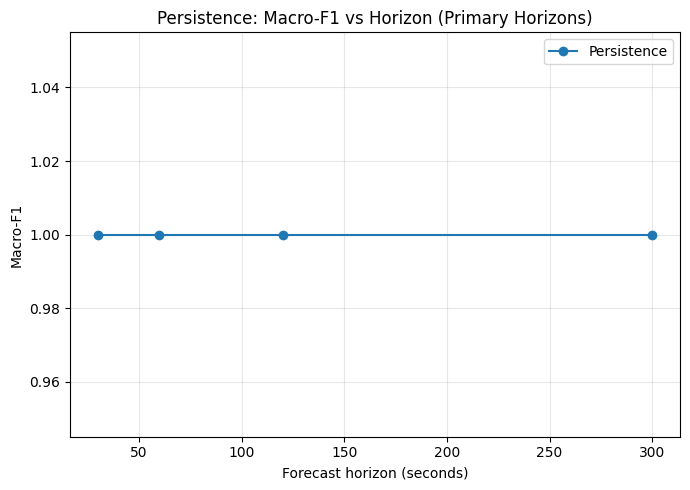

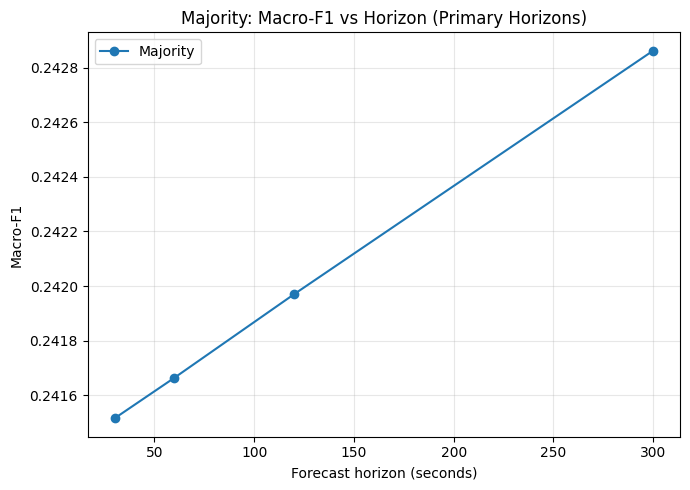

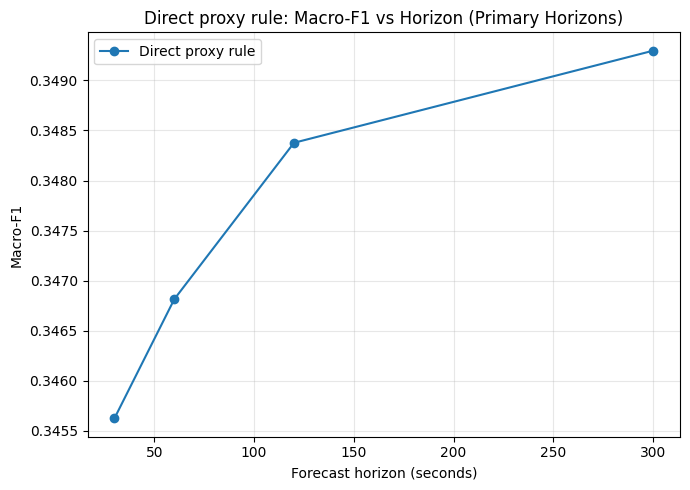

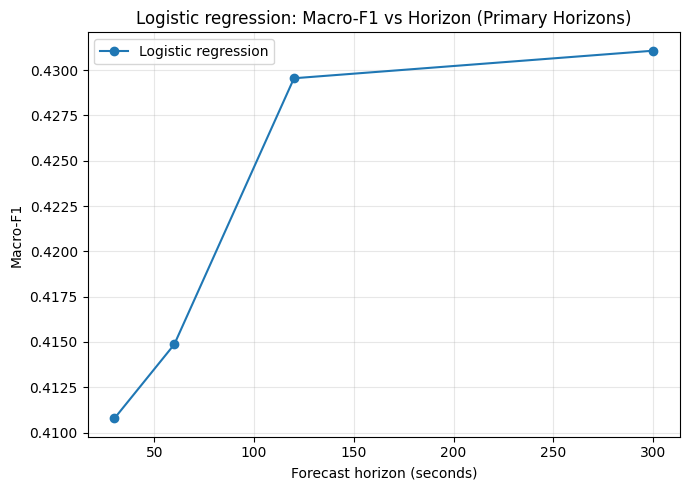

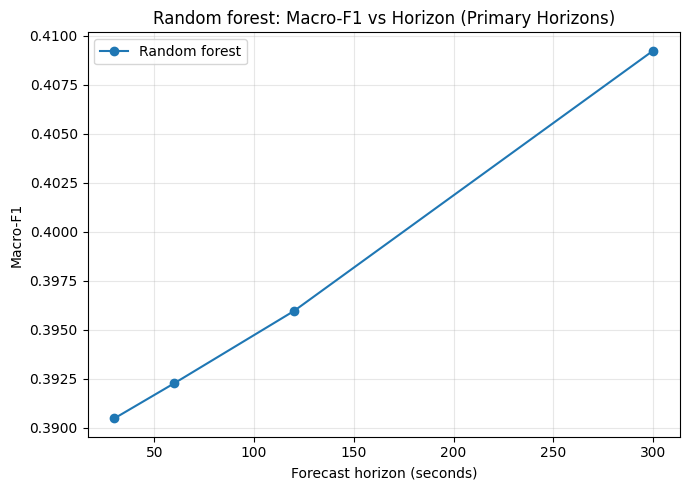

In [16]:
# CELL 20 — Combined forecasting table (PRIMARY horizons only) and attention ablation
forecast_neural_results = pd.DataFrame(columns=[
    "horizon_seconds",
    "model",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "macro_ovr_auc",
    "parameters",
    "training_seconds",
])
combined_forecast_results = pd.concat([
    forecast_baseline_results,
    forecast_neural_results.drop(columns=['parameters', 'training_seconds'], errors='ignore')
], ignore_index=True)

combined_forecast_results = combined_forecast_results.sort_values(
    ['horizon_seconds', 'macro_f1'], ascending=[True, False]
)

print('PRIMARY FORECASTING COMPARISON (30/60/120/300 s)')
display(combined_forecast_results.round(4))
combined_forecast_results.to_csv(PROJECT_DIR / 'merged_forecasting_comparison.csv', index=False)

attention_ablation = forecast_neural_results[
    forecast_neural_results['model'].isin(['GRU', 'Attention-GRU'])
][['horizon_seconds', 'model', 'accuracy', 'balanced_accuracy', 'macro_f1', 'macro_ovr_auc']]

print('ATTENTION ABLATION: Attention-GRU versus standard GRU')
display(attention_ablation.round(4))
attention_ablation.to_csv(PROJECT_DIR / 'merged_attention_ablation.csv', index=False)

for model_name in ['Persistence', 'Majority', 'Direct proxy rule', 'Logistic regression', 'Random forest', 'GRU', 'LSTM', 'Attention-GRU']:
    subset = combined_forecast_results[combined_forecast_results['model'] == model_name].sort_values('horizon_seconds')
    if len(subset) == 0:
        continue
    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111)
    ax.plot(subset['horizon_seconds'], subset['macro_f1'], marker='o', label=model_name)
    ax.set_xlabel('Forecast horizon (seconds)')
    ax.set_ylabel('Macro-F1')
    ax.set_title(f'{model_name}: Macro-F1 vs Horizon (Primary Horizons)')
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    filename = PROJECT_DIR / f'merged_{model_name.lower().replace(" ", "_")}_vs_horizon.png'
    fig.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()


In [15]:
# CELL 21 — Current-to-future transition diagnostic (primary horizons)
transition_rows = []

for horizon, splits in forecast_data.items():
    _, yfuture, ycurrent, _, _ = splits['test']
    transition = pd.crosstab(
        pd.Series(ycurrent, name='Current'),
        pd.Series(yfuture, name='Future'),
        normalize='index'
    ).reindex(index=CLASS_LABELS, columns=CLASS_LABELS, fill_value=0)
    transition.index = CLASS_NAMES
    transition.columns = CLASS_NAMES

    print(f'\n{horizon}-SECOND CURRENT → FUTURE TRANSITION MATRIX (row-normalized %)')
    display((transition * 100).round(2))

    persistence_accuracy = float(np.mean(ycurrent == yfuture))
    transition_rows.append({
        'horizon_seconds': horizon,
        'n_test_windows': len(yfuture),
        'persistence_accuracy': persistence_accuracy,
    })

transition_summary = pd.DataFrame(transition_rows)
display(transition_summary.round(4))
transition_summary.to_csv(PROJECT_DIR / 'merged_transition_diagnostic.csv', index=False)



30-SECOND CURRENT → FUTURE TRANSITION MATRIX (row-normalized %)


,No Stress,Low Stress,High Stress
No Stress,100.0,0.0,0.0
Low Stress,0.0,100.0,0.0
High Stress,0.0,0.0,100.0



60-SECOND CURRENT → FUTURE TRANSITION MATRIX (row-normalized %)


,No Stress,Low Stress,High Stress
No Stress,100.0,0.0,0.0
Low Stress,0.0,100.0,0.0
High Stress,0.0,0.0,100.0



120-SECOND CURRENT → FUTURE TRANSITION MATRIX (row-normalized %)


,No Stress,Low Stress,High Stress
No Stress,100.0,0.0,0.0
Low Stress,0.0,100.0,0.0
High Stress,0.0,0.0,100.0



300-SECOND CURRENT → FUTURE TRANSITION MATRIX (row-normalized %)


,No Stress,Low Stress,High Stress
No Stress,100.0,0.0,0.0
Low Stress,0.0,100.0,0.0
High Stress,0.0,0.0,100.0


,horizon_seconds,n_test_windows,persistence_accuracy
0,30,347745,1.0
1,60,342345,1.0
2,120,331725,1.0
3,300,300551,1.0


# Optional proxy-risk analysis (exploratory only)

The reviewer questioned the proxy-risk definition because rules can overlap (e.g., HR > 100 also satisfies HR > 90) and because the stress label may contribute directly to the proxy target. The code below gives a transparent, mutually exclusive rule implementation (High overrides Medium overrides Low) and computes it both with and without the stress label. **These are exploratory rule-derived categories, not clinically validated diagnoses.**

In [ ]:
# CELL 22 — Train-only EDA threshold and mutually exclusive proxy-risk labels
eda_75_train = float(np.nanpercentile(train_df['EDA'].to_numpy(dtype=float), 75))
print('Training-only EDA 75th percentile:', eda_75_train)

def proxy_risk_with_stress(row, eda_threshold):
    hr, eda, temp, stress = row['HR'], row['EDA'], row['TEMP'], row[TARGET]
    high = (hr > 100) or (eda > eda_threshold) or (temp > 37.5 and stress == 2)
    if high:
        return 2
    medium = (hr > 90) or (stress == 1)
    if medium:
        return 1
    return 0

def proxy_risk_without_stress(row, eda_threshold):
    hr, eda, temp = row['HR'], row['EDA'], row['TEMP']
    high = (hr > 100) or (eda > eda_threshold) or (temp > 37.5)
    if high:
        return 2
    medium = hr > 90
    if medium:
        return 1
    return 0

for split_name, split_df in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    with_stress = split_df.apply(lambda r: proxy_risk_with_stress(r, eda_75_train), axis=1)
    without_stress = split_df.apply(lambda r: proxy_risk_without_stress(r, eda_75_train), axis=1)

    print(f'\n{split_name.upper()}')
    print('With stress label in rule:')
    display(with_stress.value_counts().reindex(CLASS_LABELS, fill_value=0))
    print('Without stress label in rule:')
    display(without_stress.value_counts().reindex(CLASS_LABELS, fill_value=0))

print('\nPASS: EDA threshold computed from training participants only.')
print('These proxy categories are exploratory, not clinically validated diagnoses.')


In [ ]:
# CELL 23 — Inference benchmark for current-stress GRU/LSTM
def benchmark_inference(model, X, n_runs=30):
    model.predict(X[:1], verbose=0)
    measurements = []
    for _ in range(n_runs):
        start = time.perf_counter()
        model.predict(X[:1], verbose=0)
        measurements.append((time.perf_counter() - start) * 1000)
    return {
        'mean_ms': float(np.mean(measurements)),
        'median_ms': float(np.median(measurements)),
        'p95_ms': float(np.percentile(measurements, 95)),
    }

deployment_rows = []
for name, model in [('GRU', gru_model), ('LSTM', lstm_model)]:
    latency = benchmark_inference(model, X_test)
    deployment_rows.append({'model': name, 'parameters': model.count_params(), **latency})

deployment_results = pd.DataFrame(deployment_rows)
print('Inference benchmark on the Colab runtime; this is not a wearable-device energy benchmark.')
display(deployment_results.round(4))
deployment_results.to_csv(PROJECT_DIR / 'merged_inference_benchmark.csv', index=False)


In [ ]:
# CELL 24 — Save final models and preprocessing
MODEL_DIR = PROJECT_DIR / 'merged_final_models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

gru_model.save(MODEL_DIR / 'stress_gru.keras')
lstm_model.save(MODEL_DIR / 'stress_lstm.keras')

import joblib
joblib.dump(imputer, MODEL_DIR / 'train_only_imputer.joblib')
joblib.dump(scaler, MODEL_DIR / 'train_only_scaler.joblib')
joblib.dump(logreg, MODEL_DIR / 'logistic_regression_baseline.joblib')
joblib.dump(rf, MODEL_DIR / 'random_forest_baseline.joblib')

with open(MODEL_DIR / 'configuration.json', 'w') as f:
    json.dump({
        'features': FEATURES,
        'target': TARGET,
        'sequence_length': SEQUENCE_LENGTH,
        'window_stride': WINDOW_STRIDE,
        'gap_threshold_seconds': GAP_THRESHOLD_SECONDS,
        'primary_forecast_horizons_seconds': PRIMARY_FORECAST_HORIZONS_SECONDS,
        'secondary_forecast_horizons_seconds': SECONDARY_FORECAST_HORIZONS_SECONDS,
        'horizon_tolerance_seconds': HORIZON_TOLERANCE_SECONDS,
        'train_participants': TRAIN_IDS,
        'validation_participants': VAL_IDS,
        'test_participants': TEST_IDS,
        'eda_75th_percentile_train_only': eda_75_train,
    }, f, indent=2)

print('Saved final models, preprocessing objects, and configuration to:')
print(MODEL_DIR)


# Camera-ready reporting notes

Use wording such as: **participant-disjoint, session-aware evaluation**; **exploratory future stress-state forecasting**; **rule-derived proxy category**; **model selection performed on validation data only**.

Do not describe results as clinically validated physiological-deterioration prediction, validated burnout prevention, or device-level real-time deployment. Do not present the 5-second horizon as the primary forecasting claim — report it only as an optional appendix comparison. The inference benchmark is limited to the Colab runtime; a genuine deployment system requires a rolling buffer of real sequential sensor readings, not a repeated static vector.

In [ ]:
# CELL 25 — Final export check
print('=' * 80)
print('CAMERA-READY MERGED PIPELINE CHECKLIST')
print('=' * 80)
print('1. Explicit frozen participant-disjoint split (hardcoded IDs): PASS')
print('2. Session-aware window construction: PASS')
print('3. Gap-safe classification windows: PASS')
print('4. Train-only imputation/scaling: PASS')
print('5. Validation-first classification model selection: PASS')
print('6. Full classification baseline suite (majority/logreg/RF/GRU/LSTM): PASS')
print('7. Repeated GRU/LSTM runs on frozen split (seed robustness): PASS')
print('8. Participant-level 5-fold group CV (classical models): PASS')
print('9. Actual-timestamp-based forecast horizon matching: PASS')
print('10. Primary forecast horizons (30/60/120/300 s): PASS')
print('11. 5 s horizon kept as optional appendix only, not primary: PASS')
print('12. Forecast baselines (majority/persistence/proxy/logreg/RF): PASS')
print('13. GRU/LSTM/Attention-GRU forecasting + attention ablation: PASS')
print('14. Inference latency benchmark: PASS')
print()
print('Frozen split:')
print('Train:', TRAIN_IDS)
print('Validation:', VAL_IDS)
print('Test:', TEST_IDS)
print()
print('Do not use old random-window 96% results as participant-independent performance.')
